# EMTAB — Nivolumab: Multi-Omic Analysis Cohort
**Source:** Ross-Macdonald P, Walsh AM, Chasalow SD, et al., *Journal for ImmunoTherapy of Cancer* 2021 — `E-MTAB-3218.sdrf.txt`  
**Scope:** Nivolumab arm · patient data with Array assay


| Module | File | Role |
|---|---|---|
| `utils` | `src/utils/utils.py` | I/O, cohort building, survival, mutations |
| `plots` | `src/utils/plots.py` | histograms, response bar/box, categorical box, corr heatmap, missing heatmap |
| `data_formatting` | `src/utils/data_formatting.py` | `extract_patient_info`, `match_patients` |

In [1]:
# ── Paths & sys.path ───────────────────────────────────────────────────────
import sys, pathlib, warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = pathlib.Path().resolve().parent   # notebooks/ → project root
SRC_PATH     = PROJECT_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

TXT_file = PROJECT_ROOT / 'response-prediction'/'data' / 'raw' / 'EMTAB' / 'E-MTAB-3218-2'/ 'E-MTAB-3218.sdrf.txt'

print('Project root:', PROJECT_ROOT)


Project root: /Users/rubysharma/Library/CloudStorage/Dropbox


In [ ]:
# ── Imports ────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines.utils import median_survival_times
import warnings
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
from typing import Literal
from typing import Literal
from scipy import stats
import re
from collections import Counter
import seaborn as sns

# ── Project utilities ──────────────────────────────────────────────────────
from src.utils.plots import (
    plot_histograms, 
    plot_response_barplots,
    plot_response_boxplots, 
    plot_expression_qc, 
    plot_categorical_boxplot,
    missin_val_heatmap,
    plot_clinical_pca )

from src.utils.data_formatting import ( standarize_sex_colum, 
                                        extract_patient_info,
                                        match_patients,
                                        select_representative_probes )
from src.utils.helper_func import cohort_characterisation_table

from src.utils.config import load_config

sns.set_theme(style='whitegrid', font_scale=1.05)
print('Imports OK.')

Imports OK.


In [3]:
# ── Load Configurations ────────────────────────────────────────────────────────────────
args = {"config":"configs/Params_set.yml"}

cfg = load_config(args["config"])


In [4]:
pd.set_option('display.max_columns', None)

---
## PART A — Cohort Construction
### A1. Load Full Dataset 

In [5]:
EMTAB_clinical = pd.read_csv(filepath_or_buffer= TXT_file, sep="\t")

In [6]:
EMTAB_clinical.head(5)

,Source Name,Characteristics[organism],Characteristics[disease],Characteristics[individual],Characteristics[sex],Characteristics[clinical history],Characteristics[biopsy timepoint],Characteristics[clinical trial arm],Characteristics[BOR],Characteristics[BOR3],Characteristics[MPCT],Characteristics[MPCTrank],Characteristics[Response20pct],Characteristics[OS],Characteristics[PFS],Characteristics[OS_SOR],Characteristics[PFS_SOR],Characteristics[TMB],Characteristics[CD8PERCENT BL],Characteristics[CD4PERCENT BL],Characteristics[PD1PERCENT BL],Characteristics[PDL1 PERCENT],Characteristics[PDL1cat],Characteristics[TP_strelka],Characteristics[TP_Tnsnv],Characteristics[TH_strelka_cluster_count],Characteristics[TH_Tnsnv_cluster_count],Characteristics[Subject_Affy_Status],Characteristics[MatchedLesionBiopsy],Characteristics[PBRM1],Characteristics[VHL],Characteristics[BAP1],Characteristics[SETD2],Characteristics[BiopsySite],Characteristics[Biopsy Lesion],Characteristics[MPCTBiopsy],Material Type,Protocol REF,Extract Name,Protocol REF.1,Labeled Extract Name,Label,Protocol REF.2,Assay Name,Technology Type,Array Design REF,Term Source REF,Protocol REF.3,Array Data File,Comment [ArrayExpress FTP file],Factor Value[compound],Factor Value[dose],Unit[concentration unit]
0,100_PRE,Homo sapiens,clear cell renal carcinoma,100,female,PriorTherapy_Yes,Screen,B,SD,SD,5.223881,51,Not20pct,798,184,1,1,NaN,NaN,NaN,NaN,0.0,0%,12.831556,NaN,1.0,NaN,17Pre,False,NaN,NaN,NaN,NaN,Adrenal,A,12.068966,organism part,P-MTAB-42749,100_PRE,P-MTAB-42745,100_PRE:biotin,biotin,P-MTAB-42746,5500994180307022414440_E03,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994180307022414440_E03.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,2.0,milligram per kilogram
1,102_POST,Homo sapiens,clear cell renal carcinoma,102,male,PriorTherapy_Yes,Week4,A,SD,SD,3.030303,43,Not20pct,165,108,1,0,62.0,7.50,0.55,7.62,0.0,0%,44.170382,44.575574,4.0,3.0,42Pairs,True,WT,Missense_Mutation,WT,Nonsense_Mutation,SoftTissue,D,NaN,organism part,P-MTAB-42749,102_POST,P-MTAB-42745,102_POST:biotin,biotin,P-MTAB-42746,5500994180307022414440_G01,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994180307022414440_G01.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,0.3,milligram per kilogram
2,102_PRE,Homo sapiens,clear cell renal carcinoma,102,male,PriorTherapy_Yes,Screen,A,SD,SD,3.030303,43,Not20pct,165,108,1,0,62.0,7.50,0.55,7.62,0.0,0%,44.170382,44.575574,4.0,3.0,42Pairs,True,WT,Missense_Mutation,WT,Nonsense_Mutation,SoftTissue,D,NaN,organism part,P-MTAB-42749,102_PRE,P-MTAB-42745,102_PRE:biotin,biotin,P-MTAB-42746,5500994180307022414440_F01,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994180307022414440_F01.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,0.3,milligram per kilogram
3,103_POST,Homo sapiens,clear cell renal carcinoma,103,male,PriorTherapy_Yes,Week4,C,SD,SD,3.571429,45,Not20pct,862,289,1,0,5.0,NaN,NaN,NaN,NaN,NaN,10.567825,21.730915,1.0,1.0,13Post,True,WT,WT,WT,WT,SoftTissue,B,18.181818,organism part,P-MTAB-42749,103_POST,P-MTAB-42745,103_POST:biotin,biotin,P-MTAB-42746,5500994180307022414440_G05,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994180307022414440_G05.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram
4,105_POST,Homo sapiens,clear cell renal carcinoma,105,male,PriorTherapy_Yes,Week4,C,PD,PD,16.666667,68,Not20pct,118,45,0,0,72.0,0.13,0.00,0.42,0.0,0%,70.122411,70.050709,4.0,3.0,42Pairs,False,WT,WT,WT,WT,SoftTissue,C,12.121212,organism part,P-MTAB-42749,105_POST,P-MTAB-42745,105_POST:biotin,biotin,P-MTAB-42746,5500994154005050413582_F07,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_F07.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram


### A2. Clinical data contains both pre and post Nivolumab treatment, we will use pre-treatment clinical and microarray information. We remove patient for which there is no recist information available.

In [7]:
# Selecting only Pre-treament clinical information
Treat_time = [re.search('P[A-Z]+', item).group() for item in EMTAB_clinical["Source Name"]]
indices = [i for i, x in enumerate(Treat_time) if x == "PRE"]
EMTAB_clinic_filt = EMTAB_clinical.iloc[indices, :]

# Removing not estimated RECIST outcomes
EMTAB_clinic_filt = EMTAB_clinic_filt.loc[EMTAB_clinic_filt["Characteristics[BOR]"].isin(["PD", "SD", "PR", "CRPR", "CR"])]

print(EMTAB_clinic_filt["Characteristics[BOR]"].value_counts())

print(EMTAB_clinic_filt["Characteristics[individual]"].duplicated().any())

Characteristics[BOR]
SD    28
PD    19
PR     7
CR     2
Name: count, dtype: int64
False


In [8]:
# remove the word 'charatersitics' from column name
EMTAB_clinic_filt.columns = [re.sub(r'Characteristics\[(.+?)\]', r'\1', col) for col in EMTAB_clinic_filt.columns]

EMTAB_clinic_filt["PFS_months"] = EMTAB_clinic_filt["PFS"] / 30.4375
EMTAB_clinic_filt["OS_months"] = EMTAB_clinic_filt["OS"] / 30.4375


In [9]:
# Mutation status was simplified to a binary variable (mutated vs. wild-type), regardless of mutation type
EMTAB_clinic_filt.loc[~EMTAB_clinic_filt["PBRM1"].isin(["WT", np.nan]), "PBRM1"] = "MUT"
EMTAB_clinic_filt.loc[~EMTAB_clinic_filt["SETD2"].isin(["WT", np.nan]), "SETD2"] = "MUT"
EMTAB_clinic_filt.loc[~EMTAB_clinic_filt["BAP1"].isin(["WT", np.nan]), "BAP1"] = "MUT"
EMTAB_clinic_filt.loc[~EMTAB_clinic_filt["VHL"].isin(["WT", np.nan]), "VHL"] = "MUT"



In [10]:
EMTAB_clinic_filt.head()

,Source Name,organism,disease,individual,sex,clinical history,biopsy timepoint,clinical trial arm,BOR,BOR3,MPCT,MPCTrank,Response20pct,OS,PFS,OS_SOR,PFS_SOR,TMB,CD8PERCENT BL,CD4PERCENT BL,PD1PERCENT BL,PDL1 PERCENT,PDL1cat,TP_strelka,TP_Tnsnv,TH_strelka_cluster_count,TH_Tnsnv_cluster_count,Subject_Affy_Status,MatchedLesionBiopsy,PBRM1,VHL,BAP1,SETD2,BiopsySite,Biopsy Lesion,MPCTBiopsy,Material Type,Protocol REF,Extract Name,Protocol REF.1,Labeled Extract Name,Label,Protocol REF.2,Assay Name,Technology Type,Array Design REF,Term Source REF,Protocol REF.3,Array Data File,Comment [ArrayExpress FTP file],Factor Value[compound],Factor Value[dose],Unit[concentration unit],PFS_months,OS_months
0,100_PRE,Homo sapiens,clear cell renal carcinoma,100,female,PriorTherapy_Yes,Screen,B,SD,SD,5.223881,51,Not20pct,798,184,1,1,NaN,NaN,NaN,NaN,0.0,0%,12.831556,NaN,1.0,NaN,17Pre,False,NaN,NaN,NaN,NaN,Adrenal,A,12.068966,organism part,P-MTAB-42749,100_PRE,P-MTAB-42745,100_PRE:biotin,biotin,P-MTAB-42746,5500994180307022414440_E03,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994180307022414440_E03.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,2.0,milligram per kilogram,6.045175,26.217659
2,102_PRE,Homo sapiens,clear cell renal carcinoma,102,male,PriorTherapy_Yes,Screen,A,SD,SD,3.030303,43,Not20pct,165,108,1,0,62.0,7.50,0.55,7.62,0.0,0%,44.170382,44.575574,4.0,3.0,42Pairs,True,WT,MUT,WT,MUT,SoftTissue,D,NaN,organism part,P-MTAB-42749,102_PRE,P-MTAB-42745,102_PRE:biotin,biotin,P-MTAB-42746,5500994180307022414440_F01,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994180307022414440_F01.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,0.3,milligram per kilogram,3.548255,5.420945
5,105_PRE,Homo sapiens,clear cell renal carcinoma,105,male,PriorTherapy_Yes,Screen,C,PD,PD,16.666667,68,Not20pct,118,45,0,0,72.0,0.13,0.00,0.42,0.0,0%,70.122411,70.050709,4.0,3.0,42Pairs,False,WT,WT,WT,WT,SoftTissue,K,NaN,organism part,P-MTAB-42749,105_PRE,P-MTAB-42745,105_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_A02,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_A02.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram,1.478439,3.876797
6,106_PRE,Homo sapiens,clear cell renal carcinoma,106,female,PriorTherapy_Yes,Screen,B,PR,CRPR,-60.666667,7,20pctDec,870,821,1,1,36.0,1.64,0.00,2.43,0.0,0%,26.632411,33.069144,1.0,2.0,17Pre,False,MUT,MUT,WT,MUT,SoftTissue,N,NaN,organism part,P-MTAB-42749,106_PRE,P-MTAB-42745,106_PRE:biotin,biotin,P-MTAB-42746,5500994180307022414440_C03,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994180307022414440_C03.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,2.0,milligram per kilogram,26.973306,28.583162
8,107_PRE,Homo sapiens,clear cell renal carcinoma,107,male,PriorTherapy_Yes,Screen,C,SD,SD,1.935484,41,Not20pct,817,529,1,0,NaN,NaN,NaN,NaN,1.0,1to5%,NaN,NaN,NaN,NaN,42Pairs,True,NaN,NaN,NaN,NaN,LymphNode,A,-8.333333,organism part,P-MTAB-42749,107_PRE,P-MTAB-42745,107_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_F12,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_F12.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram,17.379877,26.841889


---
## PART B — Classifying patients as Responders and Non-Responders

### B1. Tumor shrinkage according per ORR category
##### The following figure shows CR and PR patients with most tumor shrinkage whereas PD and SD patients with increased tumor size or with no change after treatment. However, few SD patients has tumor shrinkage which overlaps with PR patients.

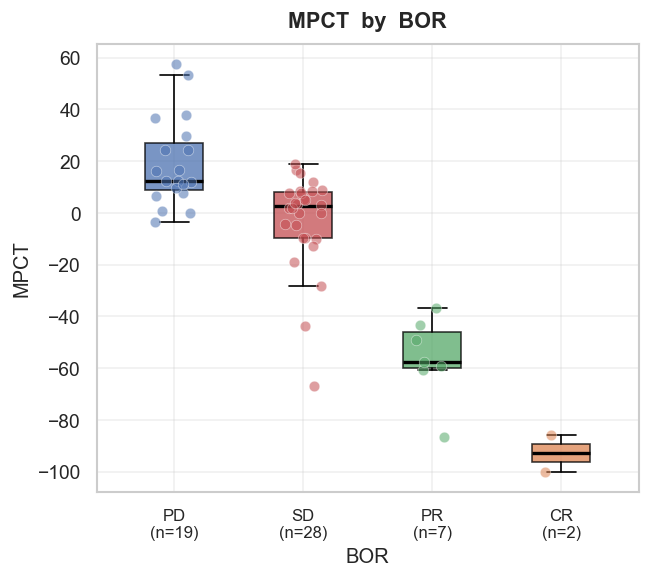

In [11]:


fig = plot_categorical_boxplot(EMTAB_clinic_filt, "BOR", "MPCT", order=["PD", "SD", "PR", "CR"], show = True)

### B2. Progression free survival per ORR category
##### The following figure shows CR and PR patients with more than six months progression free survival. PD and SD patients with less than six months progression free survival. However, some SD patients has progression free survival more than six months which overlaps with PR patients.

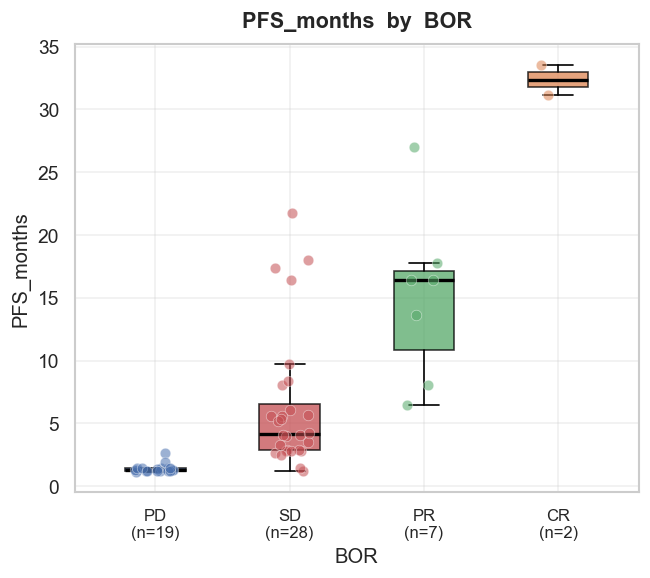

In [12]:

fig = plot_categorical_boxplot(EMTAB_clinic_filt, "BOR", "PFS_months",order=["PD", "SD", "PR", "CR"], show = True)

### B3. In order to avoid ambiguity introduced by SD patients, due to overlap with PD and (PR,CR) both in terms of tumor shrinkage and progression free survival, we are only focusing on PD, PR and CR patients. 

In [13]:
EMTAB_clinic_filt = EMTAB_clinic_filt.loc[EMTAB_clinic_filt["BOR"].isin(["CR", "PR","PD"]), :]

### B4. For our analysis we are categorizing "CR" and "PR" patients as responders and "PD" patients as non-responders.

In [14]:
EMTAB_clinic_filt.loc[EMTAB_clinic_filt["BOR"].isin(["CR", "PR"]), "Response"] = "Responders"
EMTAB_clinic_filt.loc[EMTAB_clinic_filt["BOR"].isin(["PD"]), "Response"] = "Non-Responders"

### B5. Missing Data Map

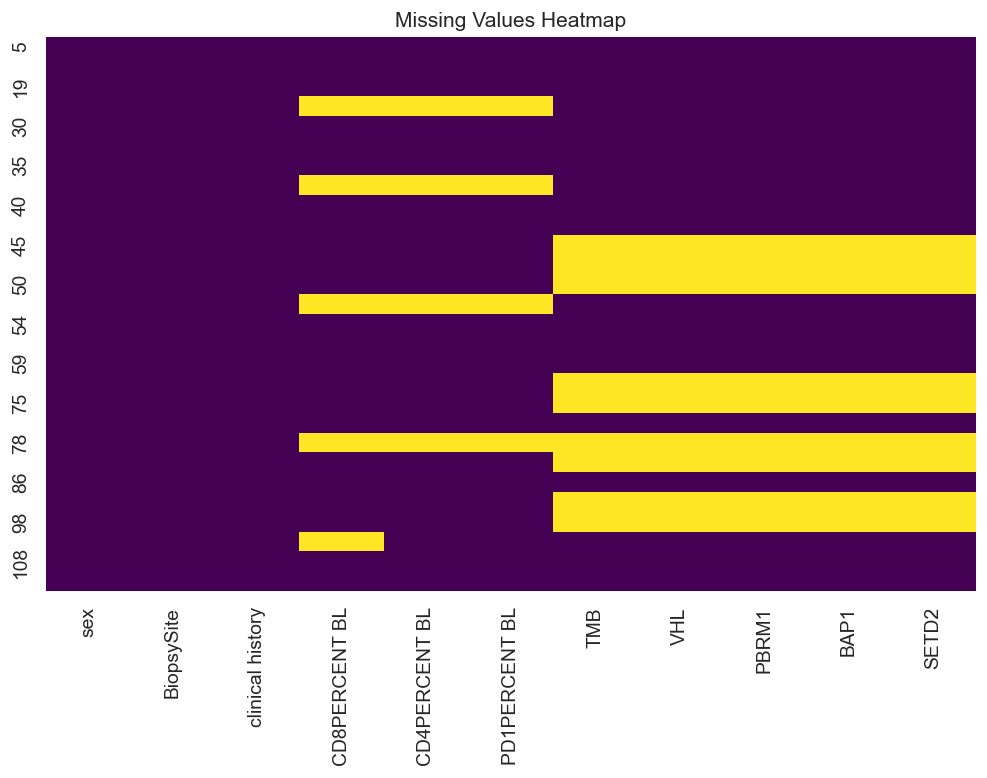

Remaining missing data in analysis cohort:
PBRM1            32.1
BAP1             32.1
TMB              32.1
SETD2            32.1
VHL              32.1
CD8PERCENT BL    17.9
PD1PERCENT BL    14.3
CD4PERCENT BL    14.3


In [15]:
# ── missin_val_heatmap from plots.py ───────────────────────────────────────
key_cols = [c for c in [
    # Demographics
    "sex",  "BiopsySite", "clinical history",

    # Immune / CD8
    "CD8PERCENT BL", "CD4PERCENT BL", "PD1PERCENT BL",
    # Genomic instability
    "TMB",
    # Top somatic mutations
    "VHL", "PBRM1", "BAP1", "SETD2",
] if c in EMTAB_clinic_filt.columns]

missin_val_heatmap(EMTAB_clinic_filt[key_cols])

miss_pct = EMTAB_clinic_filt[key_cols].isnull().mean().mul(100).sort_values(ascending=False).round(1)
miss_pct = miss_pct[miss_pct > 0]
if len(miss_pct):
    print('Remaining missing data in analysis cohort:')
    print(miss_pct.to_string())
else:
    print('No missing values in key columns — cohort is fully matched.')

### B6.  Cohort Characterisation Table (Table 1) on final clinical dataset
> Stratified by Responders vs Non-Responders. Continuous features: median (IQR) + Mann-Whitney p-value. Categorical: n (%) + Chi-squared / Fisher's exact p-value.

##### Progression-free survival (PFS) and overall survival (OS) are significantly longer in responders compared to non-responders, consistent with expected clinical outcomes and confirming the validity of the response labels. PBRM1 mutation is also signifcanly different between the two groups where responder patients have more mutation compared to non-responders. We observed the same signal in CheckMate cohort. Rest of the clinical features are not significantly different between the two groups.

In [16]:
# Selected features
TABLE1_FEATURES = [
    # Demographics
    "sex",  "BiopsySite", "clinical history",'PFS_months','OS_months', "MPCT",

    # Immune / CD8
    "CD8PERCENT BL", "CD4PERCENT BL", "PD1PERCENT BL",
    # Genomic instability
    "TMB",
    # Top somatic mutations
    "VHL", "PBRM1", "BAP1", "SETD2",
]
# Keep only columns that actually exist in nivolumab table
TABLE1_FEATURES = [f for f in TABLE1_FEATURES if f in EMTAB_clinic_filt.columns]
print(f"Features available for Table 1: {len(TABLE1_FEATURES)}")
print(TABLE1_FEATURES)

Features available for Table 1: 14
['sex', 'BiopsySite', 'clinical history', 'PFS_months', 'OS_months', 'MPCT', 'CD8PERCENT BL', 'CD4PERCENT BL', 'PD1PERCENT BL', 'TMB', 'VHL', 'PBRM1', 'BAP1', 'SETD2']


In [17]:
# Binary label: clinical benefit (CB) and non-clinical benefit (NCB); drop ICB (indeterminate)
df_cb = EMTAB_clinic_filt[EMTAB_clinic_filt["Response"].isin(["Responders", "Non-Responders"])].copy()

tbl_strat = cohort_characterisation_table(
    df=df_cb,
    features=TABLE1_FEATURES,
    group_col="Response",
)
display(tbl_strat)

,Feature,Category,Overall (N=28),Non-Responders (N=19),Responders (N=9),P-value
0,sex,female,6 (21.4%),3 (15.8%),3 (33.3%),0.352
1,,male,22 (78.6%),16 (84.2%),6 (66.7%),
2,BiopsySite,Adrenal,2 (7.1%),2 (10.5%),0 (0.0%),0.454
3,,Kidney,1 (3.6%),1 (5.3%),0 (0.0%),
4,,Liver,3 (10.7%),2 (10.5%),1 (11.1%),
5,,Lung,3 (10.7%),1 (5.3%),2 (22.2%),
6,,LymphNode,3 (10.7%),1 (5.3%),2 (22.2%),
7,,Pancreas,2 (7.1%),2 (10.5%),0 (0.0%),
8,,SoftTissue,14 (50.0%),10 (52.6%),4 (44.4%),
9,clinical history,PriorTherapy_No,8 (28.6%),5 (26.3%),3 (33.3%),1.000


---
## PART C — Visualizations on Analysis Cohort

##### The following picture shows the difference in distribution of clinical variables between Responders and Non-Responders.Pfs Months(Progression free survival) and Os (overall survival) and MPCT (tum) are significanlty different betweent the two gropus.

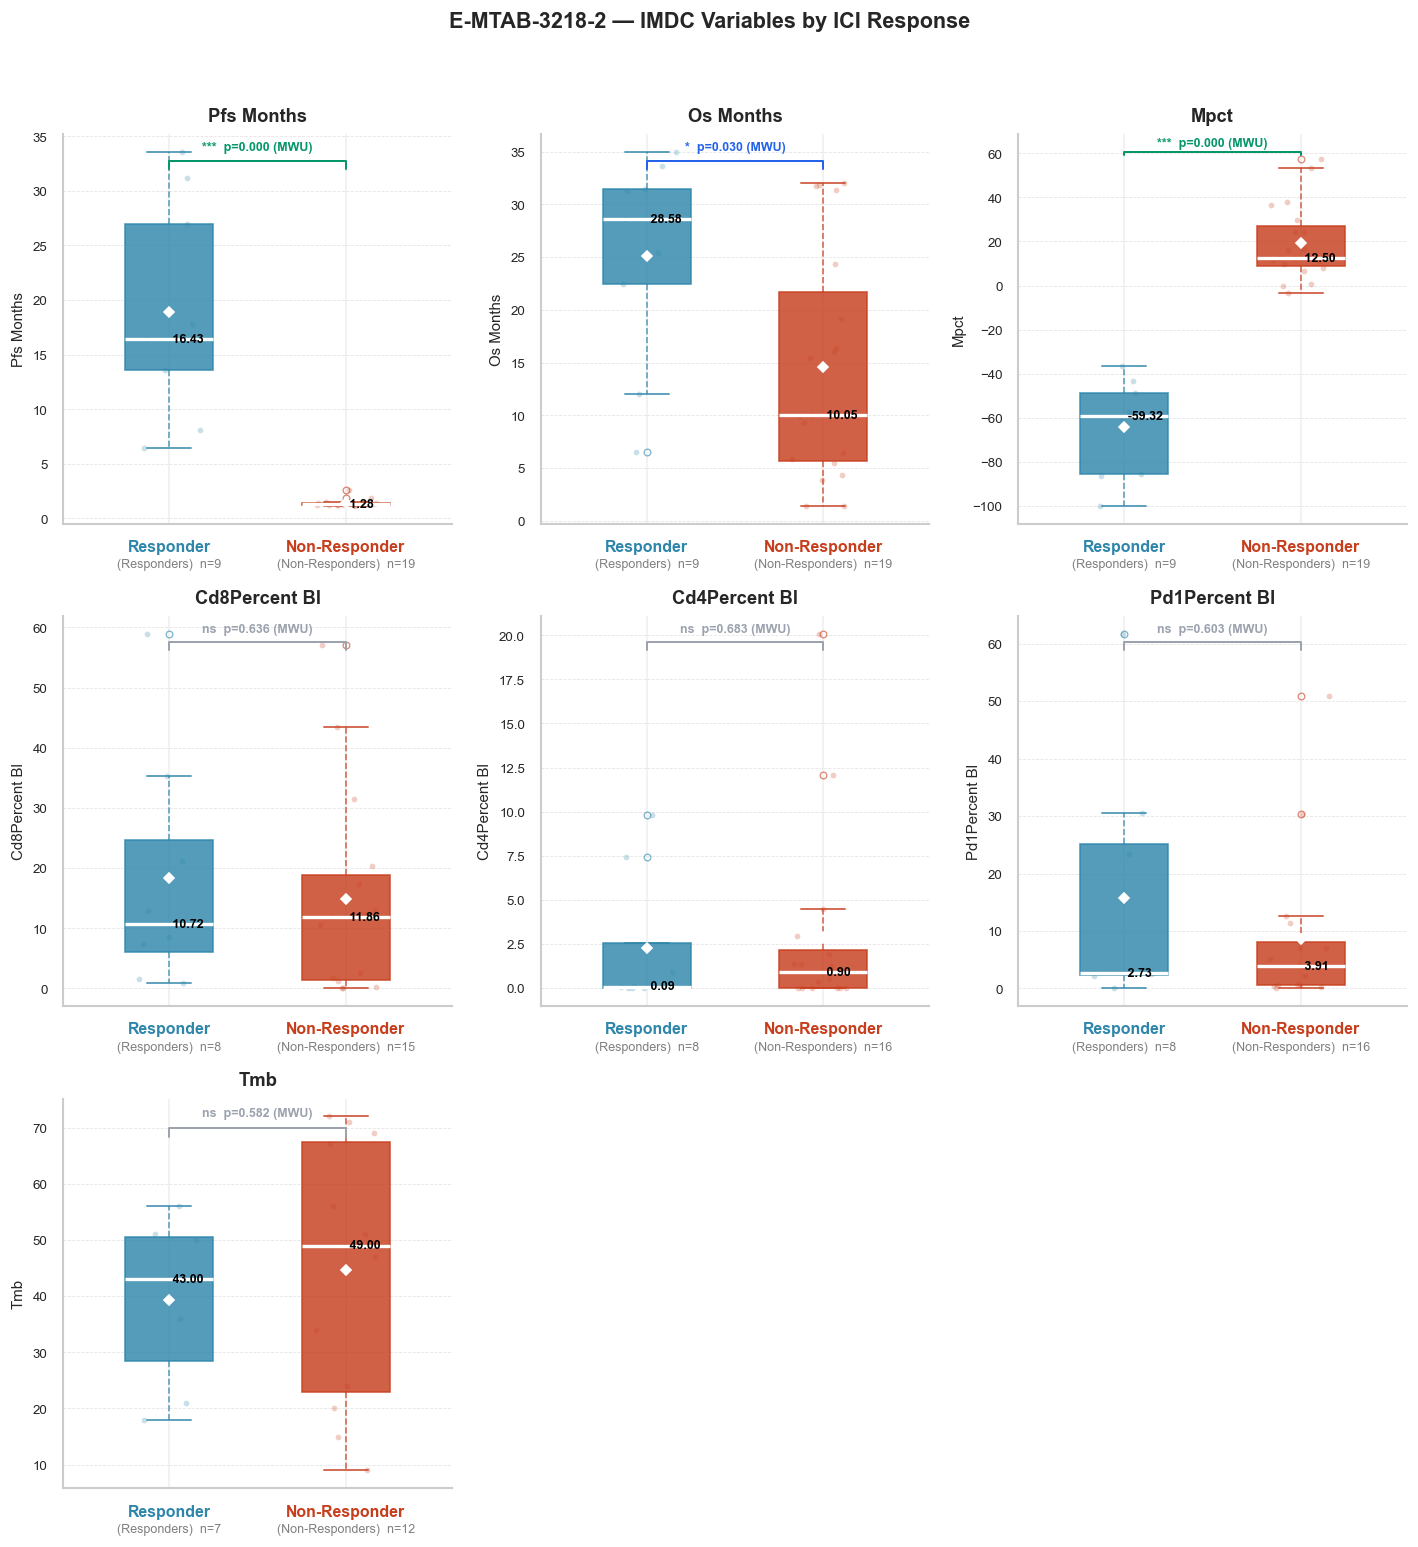

In [18]:
    
fig3 = plot_response_boxplots(
          EMTAB_clinic_filt,
          numerical_cols=['PFS_months','OS_months', "MPCT",
                           "CD8PERCENT BL", "CD4PERCENT BL", "PD1PERCENT BL", "TMB" ],
            response_col="Response",
            colors=["#2E86AB", "#C73E1D"],
            responders = [ "Responders"],
            non_responders=["Non-Responders"],
            show_points="jitter",
            show_pvalue="mannwhitney",
            title="E-MTAB-3218-2 — IMDC Variables by ICI Response"
)

---
## PART D — RNA-seq quality

In [18]:
EMTAB_expr_mat = pd.read_csv(filepath_or_buffer = "data/processed/EMTAB_expression_matrix.csv"   )

In [19]:
## Remove Probeids which are not annotated and do not have gene symbols

Probe_nt_anno = EMTAB_expr_mat.index[EMTAB_expr_mat["SYMBOL"].isnull()]
EMTAB_expr_mat = EMTAB_expr_mat.drop(Probe_nt_anno)
assert EMTAB_expr_mat["SYMBOL"].isnull().sum() == 0, f"Unannotated probeids should not exist."

In [20]:
EMTAB_rep_exp_final = select_representative_probes(EMTAB_expr_mat, "PROBEID", "SYMBOL")

In [21]:
EMTAB_rep_exp_final.head()

,SYMBOL,representative_probe_id,5500994154005050413582_A01.cel,5500994154005050413582_A02.cel,5500994154005050413582_A03.cel,5500994154005050413582_A05.cel,5500994154005050413582_A07.cel,5500994154005050413582_A08.cel,5500994154005050413582_A09.cel,5500994154005050413582_A12.cel,5500994154005050413582_B01.cel,5500994154005050413582_B02.cel,5500994154005050413582_B04.cel,5500994154005050413582_B05.cel,5500994154005050413582_B06.cel,5500994154005050413582_B07.cel,5500994154005050413582_B08.cel,5500994154005050413582_B09.cel,5500994154005050413582_B12.cel,5500994154005050413582_C01.cel,5500994154005050413582_C05.cel,5500994154005050413582_C06.cel,5500994154005050413582_C08.cel,5500994154005050413582_C11.cel,5500994154005050413582_C12.cel,5500994154005050413582_D02.cel,5500994154005050413582_D03.cel,5500994154005050413582_D05.cel,5500994154005050413582_D06.cel,5500994154005050413582_D07.cel,5500994154005050413582_D08.cel,5500994154005050413582_D10.cel,5500994154005050413582_D12.cel,5500994154005050413582_E01.cel,5500994154005050413582_E02.cel,5500994154005050413582_E04.cel,5500994154005050413582_E06.cel,5500994154005050413582_E07.cel,5500994154005050413582_E08.cel,5500994154005050413582_E09.cel,5500994154005050413582_E10.cel,5500994154005050413582_F01.cel,5500994154005050413582_F02.cel,5500994154005050413582_F03.cel,5500994154005050413582_F04.cel,5500994154005050413582_F07.cel,5500994154005050413582_F09.cel,5500994154005050413582_F10.cel,5500994154005050413582_F11.cel,5500994154005050413582_F12.cel,5500994154005050413582_G01.cel,5500994154005050413582_G02.cel,5500994154005050413582_G03.cel,5500994154005050413582_G04.cel,5500994154005050413582_G05.cel,5500994154005050413582_G06.cel,5500994154005050413582_G08.cel,5500994154005050413582_G09.cel,5500994154005050413582_G10.cel,5500994154005050413582_G11.cel,5500994154005050413582_G12.cel,5500994154005050413582_H01.cel,5500994154005050413582_H02.cel,5500994154005050413582_H03.cel,5500994154005050413582_H04.cel,5500994154005050413582_H05.cel,5500994154005050413582_H06.cel,5500994154005050413582_H07.cel,5500994154005050413582_H08.cel,5500994154005050413582_H09.cel,5500994154005050413582_H11.cel,5500994154005050413582_H12.cel,5500994180307022414440_A02.cel,5500994180307022414440_A03.cel,5500994180307022414440_A04.cel,5500994180307022414440_A05.cel,5500994180307022414440_A06.cel,5500994180307022414440_B01.cel,5500994180307022414440_B02.cel,5500994180307022414440_B03.cel,5500994180307022414440_B04.cel,5500994180307022414440_B05.cel,5500994180307022414440_C01.cel,5500994180307022414440_C03.cel,5500994180307022414440_C04.cel,5500994180307022414440_C05.cel,5500994180307022414440_C06.cel,5500994180307022414440_D02.cel,5500994180307022414440_D03.cel,5500994180307022414440_D04.cel,5500994180307022414440_D05.cel,5500994180307022414440_E01.cel,5500994180307022414440_E02.cel,5500994180307022414440_E03.cel,5500994180307022414440_E05.cel,5500994180307022414440_F01.cel,5500994180307022414440_F03.cel,5500994180307022414440_F04.cel,5500994180307022414440_G01.cel,5500994180307022414440_G04.cel,5500994180307022414440_G05.cel,5500994180307022414440_H01.cel,5500994180307022414440_H02.cel,5500994180307022414440_H03.cel,5500994180307022414440_H04.cel,5500994180307022414440_H05.cel,5501014141409120412222_A05.cel,5501014141409120412222_A07.cel,5501014141409120412222_B05.cel,5501014141409120412222_B07.cel,5501014141409120412222_C05.cel,5501014141409120412222_D05.cel,5501014141409120412222_E05.cel,5501014141409120412222_F05.cel,5501014141409120412222_G05.cel,5501014141409120412222_H05.cel
0,H3C8,11715100_at,3.749529,4.485775,6.915079,4.049993,4.794509,4.057360,4.665419,3.841151,5.099343,4.483467,3.764861,3.690262,4.605328,3.449148,4.196884,3.613883,3.332760,3.527857,3.597972,4.697538,5.179532,3.824292,3.622816,6.035818,3.265185,3.826218,5.620183,4.551347,3.495868,3.705553,4.001998,4.242322,4.003567,4.547372,4.018943,4.313471,6.463802,4.566277,3.901591,3.692876,4.240336,4.082307,3.760568,3.593295,4.576235,3.853987,3

In [22]:
columns_ned = ["SYMBOL", "representative_probe_id"] + EMTAB_clinic_filt["Array Data File"].to_list()

EMTAB_rep_exp_final = EMTAB_rep_exp_final.loc[:,EMTAB_rep_exp_final.columns.isin(columns_ned )]

In [23]:
column_order = EMTAB_rep_exp_final.columns[2:]
EMTAB_clinic_filt["Array Data File"] = pd.Categorical(EMTAB_clinic_filt["Array Data File"], categories=column_order, ordered=True)
EMTAB_clinic_filt_order = EMTAB_clinic_filt.sort_values("Array Data File")
EMTAB_clinic_filt_order.index = EMTAB_clinic_filt["Array Data File"]

In [24]:
EMTAB_rep_exp_final.head(5)

,SYMBOL,representative_probe_id,5500994154005050413582_A01.cel,5500994154005050413582_A02.cel,5500994154005050413582_A03.cel,5500994154005050413582_A08.cel,5500994154005050413582_B02.cel,5500994154005050413582_B12.cel,5500994154005050413582_C01.cel,5500994154005050413582_D02.cel,5500994154005050413582_D07.cel,5500994154005050413582_E02.cel,5500994154005050413582_E10.cel,5500994154005050413582_F01.cel,5500994154005050413582_G02.cel,5500994154005050413582_G05.cel,5500994154005050413582_H03.cel,5500994154005050413582_H06.cel,5500994154005050413582_H07.cel,5500994154005050413582_H08.cel,5500994154005050413582_H11.cel,5500994154005050413582_H12.cel,5500994180307022414440_A04.cel,5500994180307022414440_C03.cel,5500994180307022414440_D05.cel,5500994180307022414440_E02.cel,5500994180307022414440_F03.cel,5500994180307022414440_H05.cel,5501014141409120412222_C05.cel,5501014141409120412222_D05.cel
0,H3C8,11715100_at,3.749529,4.485775,6.915079,4.057360,4.483467,3.332760,3.527857,6.035818,4.551347,4.003567,3.901591,3.692876,5.219488,3.799411,3.807413,6.898778,5.675877,3.737575,4.064344,3.810243,4.786774,3.021120,3.745184,3.740167,3.083800,3.493746,3.753505,4.288901
1,TNFAIP8L1,11759187_at,5.460355,5.586533,5.255598,4.960226,5.599855,5.537662,5.897784,5.210900,5.262238,6.205730,5.714205,6.449968,4.899634,6.807276,5.827426,4.875727,5.881512,5.769429,5.883534,5.600056,5.669726,6.399416,6.244675,5.043628,6.615088,6.148662,5.071434,6.775396
2,OTOP2,11759464_at,3.310212,2.774165,3.059480,2.921263,2.724767,2.918530,3.316918,2.957897,3.034328,2.716549,2.927107,3.210191,3.154044,2.620433,2.828448,2.738860,3.278123,2.888555,3.213430,2.895027,3.165893,2.856098,2.825372,3.250916,3.055970,3.655377,2.697956,2.824849
3,C17orf78,11715105_at,2.595649,2.365130,2.754312,2.710219,2.776711,2.712330,2.501397,2.709828,2.876581,2.837417,2.537172,2.729570,3.274745,2.780501,2.780204,2.759039,2.576844,2.496914,2.739974,2.731255,2.812615,2.442704,2.493280,2.773034,2.877580,3.129859,2.848183,2.852347
4,CTAGE6,11735769_at,1.995544,2.101194,2.606097,2.251944,1.628625,1.772409,1.965281,1.937829,2.526405,3.551229,2.080074,2.237915,3.093940,2.414909,1.694230,3.332979,1.755104,1.672884,1.672057,1.778512,1.639569,2.045879,2.011514,2.293635,2.440952,1.971740,1.732044,1.686207


### D1. Exploratory QC was performed on the downloaded expression matrix to confirm data integrity prior to analysis

##### Three quality metrics were assessed on the microarray expression data. Library size distribution shows the total signal intensity per array, where a tight distribution indicates consistent hybridisation across samples. The expression density plot overlays log2 expression distributions across all samples, where well-normalised arrays should show closely aligned curve shapes. The mean-variance dispersion plot examines the relationship between average expression level and variability across probes, helping identify whether the data follows expected microarray behaviour.

##### Overall the data appears well-normalised, expression density curves are tightly overlapping across all samples, and dispersion follows the expected pattern of decreasing variance at higher expression levels. Library sizes are broadly consistent, though two samples (labelled in the outlier view) fall beyond the IQR boundaries. These samples were flagged for review.

[QC] PDF saved → results/qc_microarray/microarray_full_report.pdf
[QC] 3 plots saved to: /Users/rubysharma/Library/CloudStorage/Dropbox/response-prediction/results/qc_microarray


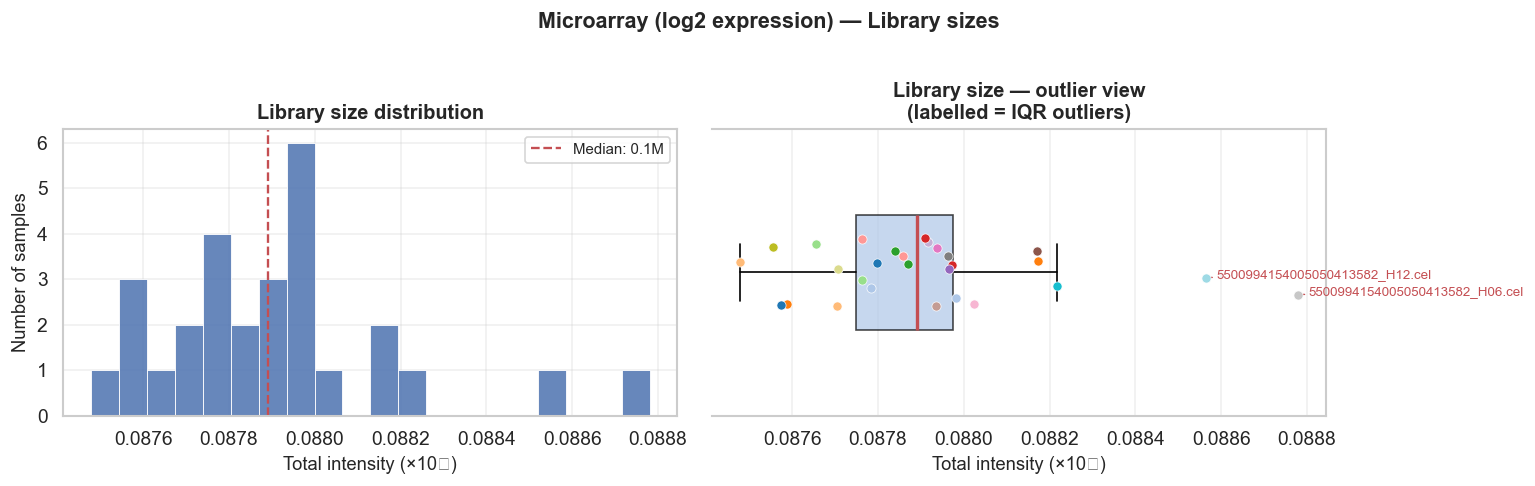

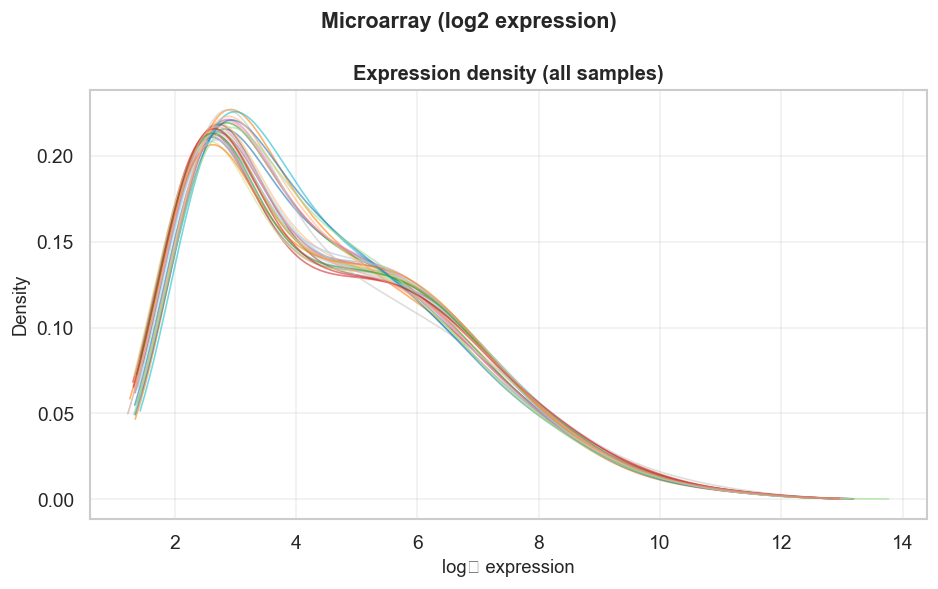

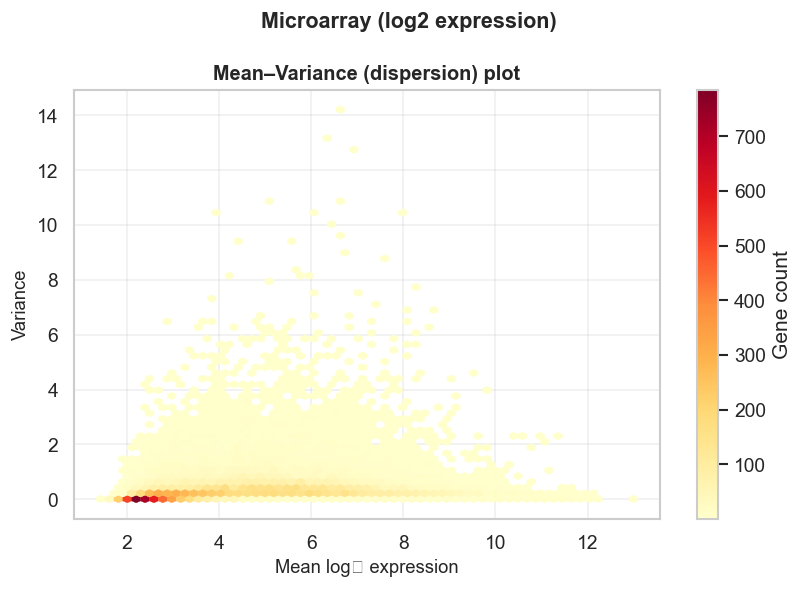

{'01_library_sizes': <Figure size 1560x480 with 2 Axes>,
 '02_density': <Figure size 960x600 with 1 Axes>,
 '03_mean_variance': <Figure size 840x600 with 2 Axes>}

In [25]:
plot_expression_qc(EMTAB_rep_exp_final.iloc[:,2:], data_type="microarray",
                       output_dir="results/qc_microarray",
                       prefix="microarray", show=True, pca_label_samples=False)

In [26]:
EMTAB_rep_exp_final.head()

,SYMBOL,representative_probe_id,5500994154005050413582_A01.cel,5500994154005050413582_A02.cel,5500994154005050413582_A03.cel,5500994154005050413582_A08.cel,5500994154005050413582_B02.cel,5500994154005050413582_B12.cel,5500994154005050413582_C01.cel,5500994154005050413582_D02.cel,5500994154005050413582_D07.cel,5500994154005050413582_E02.cel,5500994154005050413582_E10.cel,5500994154005050413582_F01.cel,5500994154005050413582_G02.cel,5500994154005050413582_G05.cel,5500994154005050413582_H03.cel,5500994154005050413582_H06.cel,5500994154005050413582_H07.cel,5500994154005050413582_H08.cel,5500994154005050413582_H11.cel,5500994154005050413582_H12.cel,5500994180307022414440_A04.cel,5500994180307022414440_C03.cel,5500994180307022414440_D05.cel,5500994180307022414440_E02.cel,5500994180307022414440_F03.cel,5500994180307022414440_H05.cel,5501014141409120412222_C05.cel,5501014141409120412222_D05.cel
0,H3C8,11715100_at,3.749529,4.485775,6.915079,4.057360,4.483467,3.332760,3.527857,6.035818,4.551347,4.003567,3.901591,3.692876,5.219488,3.799411,3.807413,6.898778,5.675877,3.737575,4.064344,3.810243,4.786774,3.021120,3.745184,3.740167,3.083800,3.493746,3.753505,4.288901
1,TNFAIP8L1,11759187_at,5.460355,5.586533,5.255598,4.960226,5.599855,5.537662,5.897784,5.210900,5.262238,6.205730,5.714205,6.449968,4.899634,6.807276,5.827426,4.875727,5.881512,5.769429,5.883534,5.600056,5.669726,6.399416,6.244675,5.043628,6.615088,6.148662,5.071434,6.775396
2,OTOP2,11759464_at,3.310212,2.774165,3.059480,2.921263,2.724767,2.918530,3.316918,2.957897,3.034328,2.716549,2.927107,3.210191,3.154044,2.620433,2.828448,2.738860,3.278123,2.888555,3.213430,2.895027,3.165893,2.856098,2.825372,3.250916,3.055970,3.655377,2.697956,2.824849
3,C17orf78,11715105_at,2.595649,2.365130,2.754312,2.710219,2.776711,2.712330,2.501397,2.709828,2.876581,2.837417,2.537172,2.729570,3.274745,2.780501,2.780204,2.759039,2.576844,2.496914,2.739974,2.731255,2.812615,2.442704,2.493280,2.773034,2.877580,3.129859,2.848183,2.852347
4,CTAGE6,11735769_at,1.995544,2.101194,2.606097,2.251944,1.628625,1.772409,1.965281,1.937829,2.526405,3.551229,2.080074,2.237915,3.093940,2.414909,1.694230,3.332979,1.755104,1.672884,1.672057,1.778512,1.639569,2.045879,2.011514,2.293635,2.440952,1.971740,1.732044,1.686207


In [27]:
EMTAB_clinic_filt_order.head()

,Source Name,organism,disease,individual,sex,clinical history,biopsy timepoint,clinical trial arm,BOR,BOR3,MPCT,MPCTrank,Response20pct,OS,PFS,OS_SOR,PFS_SOR,TMB,CD8PERCENT BL,CD4PERCENT BL,PD1PERCENT BL,PDL1 PERCENT,PDL1cat,TP_strelka,TP_Tnsnv,TH_strelka_cluster_count,TH_Tnsnv_cluster_count,Subject_Affy_Status,MatchedLesionBiopsy,PBRM1,VHL,BAP1,SETD2,BiopsySite,Biopsy Lesion,MPCTBiopsy,Material Type,Protocol REF,Extract Name,Protocol REF.1,Labeled Extract Name,Label,Protocol REF.2,Assay Name,Technology Type,Array Design REF,Term Source REF,Protocol REF.3,Array Data File,Comment [ArrayExpress FTP file],Factor Value[compound],Factor Value[dose],Unit[concentration unit],PFS_months,OS_months,Response
Array Data File,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
5500994154005050413582_A02.cel,14_PRE,Homo sapiens,clear cell renal carcinoma,14,male,PriorTherapy_No,Screen,D,PR,CRPR,-86.486486,2,20pctDec,1025,541,1,0,56.0,NaN,NaN,NaN,0.0,0%,48.915050,39.998361,4.0,2.0,17Pre,False,MUT,WT,WT,WT,LymphNode,C,NaN,organism part,P-MTAB-42749,14_PRE,P-MTAB-42745,14_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_A01,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_A01.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram,17.774127,33.675565,Responders
5500994180307022414440_C03.cel,105_PRE,Homo sapiens,clear cell renal carcinoma,105,male,PriorTherapy_Yes,Screen,C,PD,PD,16.666667,68,Not20pct,118,45,0,0,72.0,0.13,0.00,0.42,0.0,0%,70.122411,70.050709,4.0,3.0,42Pairs,False,WT,WT,WT,WT,SoftTissue,K,NaN,organism part,P-MTAB-42749,105_PRE,P-MTAB-42745,105_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_A02,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_A02.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram,1.478439,3.876797,Non-Responders
5500994180307022414440_A04.cel,22_PRE,Homo sapiens,clear cell renal carcinoma,22,male,PriorTherapy_Yes,Screen,B,PR,CRPR,-48.958333,13,20pctDec,197,197,0,0,21.0,35.26,0.00,2.71,30.0,5+%,31.145284,11.109099,3.0,1.0,17Pre,True,WT,WT,WT,WT,SoftTissue,M,NaN,organism part,P-MTAB-42749,22_PRE,P-MTAB-42745,22_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_A03,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_A03.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,2.0,milligram per kilogram,6.472279,6.472279,Responders
5500994154005050413582_A01.cel,1_PRE,Homo sapiens,clear cell renal carcinoma,1,male,PriorTherapy_Yes,Screen,C,PD,PD,24.342105,74,Not20pct,43,38,1,0,34.0,1.16,0.00,0.51,0.0,0%,44.534099,32.933363,4.0,2.0,42Pairs,False,WT,MUT,WT,WT,LymphNode,U,NaN,organism part,P-MTAB-42749,1_PRE,P-MTAB-42745,1_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_A08,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_A08.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram,1.248460,1.412731,Non-Responders
5500994154005050413582_A08.cel,66_PRE,Homo sapiens,clear cell renal carcinoma,66,male,PriorTherapy_Yes,Screen,B,PD,PD,37.837838,78,Not20pct,470,36,0,0,NaN,20.28,0.34,30.33,0.0,0%,19.357211,51.729648,1.0,1.0,17Pre,True,NaN,NaN,NaN,NaN,Adrenal,D,18.918919,organism part,P-MTAB-42749,66_PRE,P-MTAB-42745,66_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_B02,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_B02.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,2.0,milligram per kilogram,1.182752,15.441478,Non-Responders


### D2. PCA plots

##### Following PCA shows the microarray gene expression variation between Responders and Non-Responders. The colors shows the Response group.There is no clear separation between Responders and Non-Responders.

[PCA] Warning: 2 expression samples not in clinical_df — excluded: ['SYMBOL', 'representative_probe_id']
[PCA] 28 samples × 19434 features after alignment.
[PCA] Figure saved: colour=Response
[PCA] PDF saved → results/emtab/pca_clinical_pca.pdf


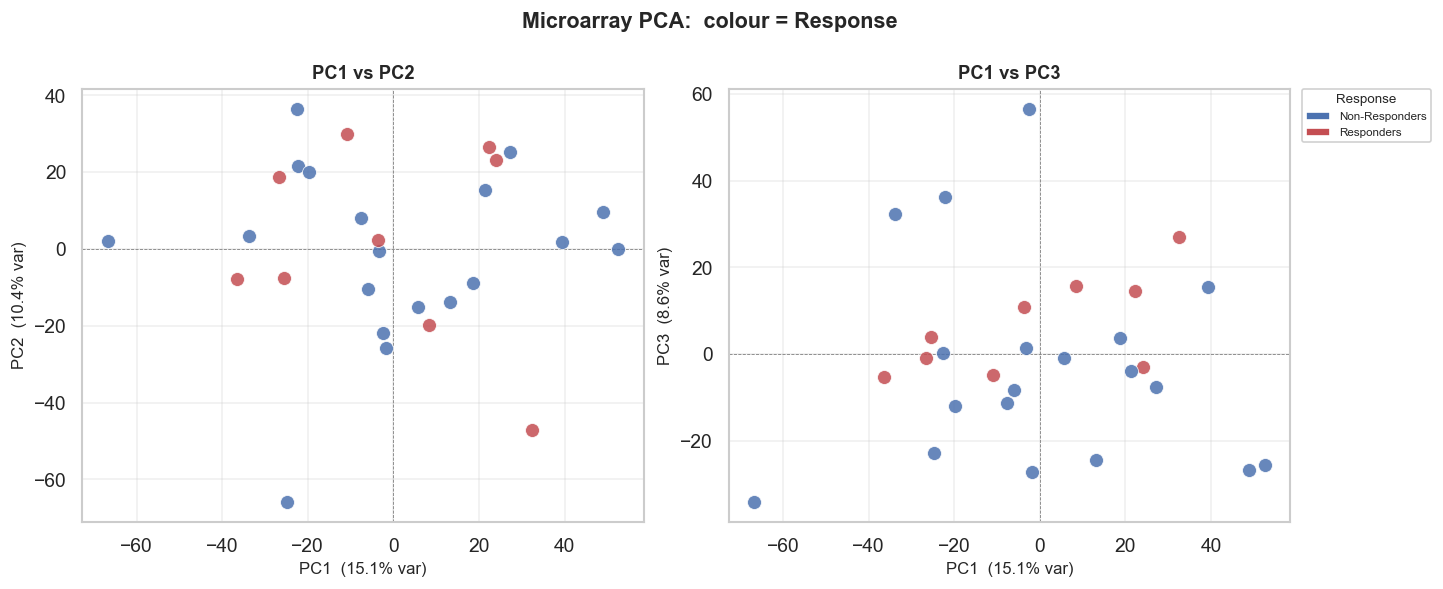

{'colour_Response': <Figure size 1440x600 with 2 Axes>}

In [28]:
plot_clinical_pca(expr_df = EMTAB_rep_exp_final,
    clinical_df =  EMTAB_clinic_filt_order,
    data_type = "microarray",
    output_dir = "results/emtab",
    pcs = [(1,2), (1,3)],
    color_cols = ["Response" ])

---
## PART E — Computing gene signature score

### E1. Standardizing the genes expression by computing z-scores

In [29]:
EMTAB_expr_z = EMTAB_rep_exp_final.iloc[:,2:].apply(
    lambda x: (x - x.mean()) / x.std(),
    axis=1
)

In [30]:
EMTAB_expr_z.head()

,5500994154005050413582_A01.cel,5500994154005050413582_A02.cel,5500994154005050413582_A03.cel,5500994154005050413582_A08.cel,5500994154005050413582_B02.cel,5500994154005050413582_B12.cel,5500994154005050413582_C01.cel,5500994154005050413582_D02.cel,5500994154005050413582_D07.cel,5500994154005050413582_E02.cel,5500994154005050413582_E10.cel,5500994154005050413582_F01.cel,5500994154005050413582_G02.cel,5500994154005050413582_G05.cel,5500994154005050413582_H03.cel,5500994154005050413582_H06.cel,5500994154005050413582_H07.cel,5500994154005050413582_H08.cel,5500994154005050413582_H11.cel,5500994154005050413582_H12.cel,5500994180307022414440_A04.cel,5500994180307022414440_C03.cel,5500994180307022414440_D05.cel,5500994180307022414440_E02.cel,5500994180307022414440_F03.cel,5500994180307022414440_H05.cel,5501014141409120412222_C05.cel,5501014141409120412222_D05.cel
0,-0.514797,0.208295,2.594194,-0.212466,0.206028,-0.924120,-0.732508,1.730643,0.272695,-0.265298,-0.365452,-0.570438,0.928899,-0.465806,-0.457947,2.578185,1.377133,-0.526538,-0.205607,-0.455168,0.503916,-1.230192,-0.519064,-0.523991,-1.168631,-0.766010,-0.510892,0.014938
1,-0.492681,-0.268480,-0.856507,-1.381341,-0.244810,-0.355317,0.284570,-0.935929,-0.844708,0.831746,-0.041625,1.265724,-1.489004,1.900611,0.159553,-1.531484,0.255656,0.056500,0.259249,-0.244452,-0.120659,1.175899,0.900947,-1.233148,1.559119,0.730346,-1.183740,1.843964
2,1.309056,-0.907260,0.272391,-0.299076,-1.111499,-0.310374,1.336785,-0.147609,0.168400,-1.145478,-0.274914,0.895514,0.663370,-1.542875,-0.682825,-1.053231,1.176381,-0.434309,0.908904,-0.407547,0.712361,-0.568504,-0.695540,1.063895,0.257877,2.736159,-1.222350,-0.697702
3,-0.699145,-1.887553,0.118818,-0.108493,0.234294,-0.097613,-1.185045,-0.110510,0.749160,0.547255,-1.000613,-0.008733,2.801840,0.253833,0.252303,0.143188,-0.796090,-1.208156,0.044901,-0.000048,0.419394,-1.487629,-1.226891,0.215337,0.754313,2.054900,0.602760,0.624226
4,-0.281886,-0.074221,0.918219,0.222094,-1.003102,-0.720481,-0.341372,-0.395330,0.761574,2.775971,-0.115734,0.194518,1.877124,0.542419,-0.874150,2.346979,-0.754495,-0.916108,-0.917733,-0.708485,-0.981591,-0.182948,-0.250495,0.304042,0.593608,-0.328675,-0.799823,-0.889919


### E2. Computing gene-signature scores
##### Published gene signatures were used as features rather than individual genes to improve stability, interpretability, and to allow comparison across the RNA-seq training data and microarray validation cohort. 

In [31]:

gene_sig_score = pd.DataFrame(index =cfg["Gene_signatures"].keys() , columns=EMTAB_expr_z.columns )
gene_sig_score = gene_sig_score.fillna(0)


for gene_sig in cfg["Gene_signatures"].keys():
   
    gene_sig_exp = EMTAB_expr_z.loc[EMTAB_rep_exp_final["SYMBOL"].isin(cfg["Gene_signatures"][gene_sig]),:]
    if gene_sig_exp.shape[0] != 0:
        column_sum = gene_sig_exp.sum()/gene_sig_exp.shape[0]
        gene_sig_score.loc[gene_sig] = column_sum.to_list()


gene_sig_score

,5500994154005050413582_A01.cel,5500994154005050413582_A02.cel,5500994154005050413582_A03.cel,5500994154005050413582_A08.cel,5500994154005050413582_B02.cel,5500994154005050413582_B12.cel,5500994154005050413582_C01.cel,5500994154005050413582_D02.cel,5500994154005050413582_D07.cel,5500994154005050413582_E02.cel,5500994154005050413582_E10.cel,5500994154005050413582_F01.cel,5500994154005050413582_G02.cel,5500994154005050413582_G05.cel,5500994154005050413582_H03.cel,5500994154005050413582_H06.cel,5500994154005050413582_H07.cel,5500994154005050413582_H08.cel,5500994154005050413582_H11.cel,5500994154005050413582_H12.cel,5500994180307022414440_A04.cel,5500994180307022414440_C03.cel,5500994180307022414440_D05.cel,5500994180307022414440_E02.cel,5500994180307022414440_F03.cel,5500994180307022414440_H05.cel,5501014141409120412222_C05.cel,5501014141409120412222_D05.cel
T_effector,0.196749,-1.249629,0.335904,-0.637247,0.084010,0.190845,1.790783,-0.532728,-0.110124,0.350966,0.339615,-1.171635,1.129288,-0.795055,1.590861,-0.265591,1.046993,1.400242,-0.400092,-0.893272,0.294987,-0.575128,-0.356622,-0.125601,-0.835491,0.730377,-0.720063,-0.813341
Angiogenesis,-0.213276,-1.213285,-0.699937,-0.074359,-1.728929,-0.081093,-0.017260,-0.055028,-0.304790,0.188194,0.156756,1.374451,-0.406664,1.135878,0.177922,-1.375485,-0.622394,-0.163343,-0.170669,0.756149,-0.325934,1.039385,0.030099,0.190267,0.908064,1.027535,-0.319611,0.787358
FAO/AMPK,1.201464,0.601988,-0.911923,-0.644113,0.151896,-0.273839,1.628888,-0.730111,-0.556145,-0.675563,-0.005412,0.354053,-0.262608,-0.461166,0.938160,-0.218873,-0.949521,-0.148510,-0.187512,0.405827,-0.015568,0.443900,0.012067,-0.821792,-0.309813,-0.131959,0.788472,0.777712
Cell_Cycle,-0.605462,0.093063,0.544757,-0.106279,0.598311,1.144611,-0.782881,0.290760,0.286464,0.312642,0.332290,0.255285,0.672166,0.059128,0.330594,0.933966,1.036511,-0.332061,-0.529880,-0.500669,-1.462302,-0.820964,-0.337088,-0.707635,0.308091,-1.268097,0.556856,-0.302179
FAS/Pentose_Phosphate,0.060638,1.079233,0.237915,-0.460072,0.695708,0.196586,0.011712,0.430592,-0.017495,0.358218,0.423142,-0.650846,-0.207195,-0.405048,-0.047552,0.483694,0.635418,-0.288241,-0.616293,-0.311076,0.096124,-0.471185,-1.354181,-0.269214,-0.214327,0.513012,0.075999,0.014734
Stroma,-1.477577,-0.277245,-0.027945,0.501169,-1.402069,0.433400,-1.451574,0.287571,0.627113,0.453118,-1.478467,0.470411,-0.382356,1.057320,-0.140631,-1.241043,1.016750,0.827932,-0.783024,0.085157,0.470951,0.603002,0.496360,1.098180,0.685031,-0.692268,-0.711665,0.952401
Myeloid_Inflammation,-0.007022,0.162433,1.301262,0.737388,-0.504501,-0.384069,-0.437578,0.650433,0.437016,-0.262415,-0.619281,-0.309082,1.056438,0.123567,-0.833629,1.168149,-0.246692,0.158506,-0.196123,-0.120263,-0.696113,-0.547749,-0.388495,-0.127142,0.189680,-0.302685,0.486481,-0.488512
Complement_Cascade,0.858854,0.091752,-1.906408,0.209353,-0.306625,-0.661127,0.297629,-0.251521,0.126403,0.765396,1.395889,-1.391341,0.415871,-0.542814,0.161756,-0.256880,-0.868470,0.864741,0.497845,-0.331273,0.040591,-0.615865,-0.468510,0.583925,0.605202,-0.575058,0.974076,0.286610
Omega_oxidation,0.797571,0.017431,-0.794917,0.074781,-0.581303,0.049318,0.321506,-0.145557,0.214661,0.585275,0.349402,-1.084470,-0.132155,-0.445335,-0.311954,0.394910,-0.798019,-0.081078,0.732666,-0.137967,-0.028226,-0.642438,0.322962,0.320198,-0.161313,0.066954,0.595117,0.501982
SnoRNA,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [32]:
EMTAB_features = pd.concat([EMTAB_clinic_filt_order , gene_sig_score.transpose()], axis = 1)

In [33]:
EMTAB_features.head(5)

,Source Name,organism,disease,individual,sex,clinical history,biopsy timepoint,clinical trial arm,BOR,BOR3,MPCT,MPCTrank,Response20pct,OS,PFS,OS_SOR,PFS_SOR,TMB,CD8PERCENT BL,CD4PERCENT BL,PD1PERCENT BL,PDL1 PERCENT,PDL1cat,TP_strelka,TP_Tnsnv,TH_strelka_cluster_count,TH_Tnsnv_cluster_count,Subject_Affy_Status,MatchedLesionBiopsy,PBRM1,VHL,BAP1,SETD2,BiopsySite,Biopsy Lesion,MPCTBiopsy,Material Type,Protocol REF,Extract Name,Protocol REF.1,Labeled Extract Name,Label,Protocol REF.2,Assay Name,Technology Type,Array Design REF,Term Source REF,Protocol REF.3,Array Data File,Comment [ArrayExpress FTP file],Factor Value[compound],Factor Value[dose],Unit[concentration unit],PFS_months,OS_months,Response,T_effector,Angiogenesis,FAO/AMPK,Cell_Cycle,FAS/Pentose_Phosphate,Stroma,Myeloid_Inflammation,Complement_Cascade,Omega_oxidation,SnoRNA,Tumor_inflammation_score
5500994154005050413582_A02.cel,14_PRE,Homo sapiens,clear cell renal carcinoma,14,male,PriorTherapy_No,Screen,D,PR,CRPR,-86.486486,2,20pctDec,1025,541,1,0,56.0,NaN,NaN,NaN,0.0,0%,48.915050,39.998361,4.0,2.0,17Pre,False,MUT,WT,WT,WT,LymphNode,C,NaN,organism part,P-MTAB-42749,14_PRE,P-MTAB-42745,14_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_A01,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_A01.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram,17.774127,33.675565,Responders,-1.249629,-1.213285,0.601988,0.093063,1.079233,-0.277245,0.162433,0.091752,0.017431,0.0,-1.271906
5500994180307022414440_C03.cel,105_PRE,Homo sapiens,clear cell renal carcinoma,105,male,PriorTherapy_Yes,Screen,C,PD,PD,16.666667,68,Not20pct,118,45,0,0,72.0,0.13,0.00,0.42,0.0,0%,70.122411,70.050709,4.0,3.0,42Pairs,False,WT,WT,WT,WT,SoftTissue,K,NaN,organism part,P-MTAB-42749,105_PRE,P-MTAB-42745,105_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_A02,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_A02.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram,1.478439,3.876797,Non-Responders,-0.575128,1.039385,0.443900,-0.820964,-0.471185,0.603002,-0.547749,-0.615865,-0.642438,0.0,-0.641897
5500994180307022414440_A04.cel,22_PRE,Homo sapiens,clear cell renal carcinoma,22,male,PriorTherapy_Yes,Screen,B,PR,CRPR,-48.958333,13,20pctDec,197,197,0,0,21.0,35.26,0.00,2.71,30.0,5+%,31.145284,11.109099,3.0,1.0,17Pre,True,WT,WT,WT,WT,SoftTissue,M,NaN,organism part,P-MTAB-42749,22_PRE,P-MTAB-42745,22_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_A03,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_A03.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,2.0,milligram per kilogram,6.472279,6.472279,Responders,0.294987,-0.325934,-0.015568,-1.462302,0.096124,0.470951,-0.696113,0.040591,-0.028226,0.0,0.047626
5500994154005050413582_A01.cel,1_PRE,Homo sapiens,clear cell renal carcinoma,1,male,PriorTherapy_Yes,Screen,C,PD,PD,24.342105,74,Not20pct,43,38,1,0,34.0,1.16,0.00,0.51,0.0,0%,44.534099,32.933363,4.0,2.0,42Pairs,False,WT,MUT,WT,WT,LymphNode,U,NaN,organism part,P-MTAB-42749,1_PRE,P-MTAB-42745,1_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_A08,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_A08.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab,10.0,milligram per kilogram,1.248460,1.412731,Non-Responders,0.196749,-0.213276,1.201464,-0.605462,0.060638,-1.477577,-0.007022,0.858854,0.797571,0.0,0.538887
5500994154005050413582_A08.cel,66_PRE,Homo sapiens,clear cell renal carcinoma,66,male,PriorTherapy_Yes,Screen,B,PD,PD,37.837838,78,Not20pct,470,36,0,0,NaN,20.28,0.34,30.33,0.0,0%,19.357211,51.729648,1.0,1.0,17Pre,True,NaN,NaN,NaN,NaN,Adrenal,D,18.918919,organism part,P-MTAB-42749,66_PRE,P-MTAB-42745,66_PRE:biotin,biotin,P-MTAB-42746,5500994154005050413582_B02,array assay,A-GEOD-19099,ArrayExpress,P-MTAB-42748,5500994154005050413582_B02.cel,ftp://ftp.ebi.ac.uk/pub/databases/microarray/d...,nivolumab

In [34]:
with pd.ExcelWriter("data/processed/EMTAB_model_features.xlsx", engine="openpyxl") as writer:
  EMTAB_features.to_excel(writer, sheet_name="Features", index=False)